In [7]:
pip install pandas numpy matplotlib seaborn jupyter

In [5]:
import pandas as pd
import io
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files
uploaded = files.upload()

Saving SampleSuperstore.csv to SampleSuperstore.csv


**Load the dataset**

In [11]:
import pandas as pd

df = pd.read_csv('SampleSuperstore.csv')
df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [15]:
# Column names and data types
df.info()
# Missing values in each column
df.isnull().sum()
# Duplicate rows
df.duplicated().sum()
# Statistical summary
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Ship Mode     9994 non-null   object 
 1   Segment       9994 non-null   object 
 2   Country       9994 non-null   object 
 3   City          9994 non-null   object 
 4   State         9994 non-null   object 
 5   Postal Code   9994 non-null   int64  
 6   Region        9994 non-null   object 
 7   Category      9994 non-null   object 
 8   Sub-Category  9994 non-null   object 
 9   Sales         9994 non-null   float64
 10  Quantity      9994 non-null   int64  
 11  Discount      9994 non-null   float64
 12  Profit        9994 non-null   float64
dtypes: float64(3), int64(2), object(8)
memory usage: 1015.1+ KB


,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55190.379428,229.858001,3.789574,0.156203,28.656896
std,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


Check the Dataset

In [14]:
# Display dataset size
print("Rows and columns:", df.shape)

# Display all column names
print(df.columns.tolist())

# Check data types and missing values
df.info()

Rows and columns: (9994, 13)
['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount', 'Profit']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Ship Mode     9994 non-null   object 
 1   Segment       9994 non-null   object 
 2   Country       9994 non-null   object 
 3   City          9994 non-null   object 
 4   State         9994 non-null   object 
 5   Postal Code   9994 non-null   int64  
 6   Region        9994 non-null   object 
 7   Category      9994 non-null   object 
 8   Sub-Category  9994 non-null   object 
 9   Sales         9994 non-null   float64
 10  Quantity      9994 non-null   int64  
 11  Discount      9994 non-null   float64
 12  Profit        9994 non-null   float64
dtypes: float64(3), int64(2), object(8)
memory usage: 1015.1+ KB


Missing Values

In [17]:
# Count missing values in each column
print(df.isnull().sum())

# Calculate percentage of missing values
missing_percent = (df.isnull().sum() / len(df)) * 100
print(missing_percent.sort_values(ascending=False))

Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64
Ship Mode       0.0
Segment         0.0
Country         0.0
City            0.0
State           0.0
Postal Code     0.0
Region          0.0
Category        0.0
Sub-Category    0.0
Sales           0.0
Quantity        0.0
Discount        0.0
Profit          0.0
dtype: float64


Remove Duplicate Rows

In [18]:
print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after:", df.duplicated().sum())

Duplicates before: 17
Duplicates after: 0


Fix date columns

In [19]:
for col in ["Order Date", "Ship Date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

print(df.dtypes)

Ship Mode        object
Segment          object
Country          object
City             object
State            object
Postal Code       int64
Region           object
Category         object
Sub-Category     object
Sales           float64
Quantity          int64
Discount        float64
Profit          float64
dtype: object


Check numerical values

In [20]:
# Check numerical column statistics
print(df.select_dtypes(include="number").describe())

        Postal Code         Sales     Quantity     Discount      Profit
count   9977.000000   9977.000000  9977.000000  9977.000000  9977.00000
mean   55154.964117    230.148902     3.790719     0.156278    28.69013
std    32058.266816    623.721409     2.226657     0.206455   234.45784
min     1040.000000      0.444000     1.000000     0.000000 -6599.97800
25%    23223.000000     17.300000     2.000000     0.000000     1.72620
50%    55901.000000     54.816000     3.000000     0.200000     8.67100
75%    90008.000000    209.970000     5.000000     0.200000    29.37200
max    99301.000000  22638.480000    14.000000     0.800000  8399.97600


Cleaned Dataset


In [21]:
print("Final dataset shape:", df.shape)
print("Remaining missing values:\n", df.isnull().sum())

df.head()

Final dataset shape: (9977, 13)
Remaining missing values:
 Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64


,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


EXPLORATORY DATA ANALYSIS(EDA)

In [22]:
# Total sales
print("Total Sales:", round(df["Sales"].sum(), 2))

# Total profit
print("Total Profit:", round(df["Profit"].sum(), 2))

# Number of unique orders
if "Order ID" in df.columns:
    print("Total Orders:", df["Order ID"].nunique())

Total Sales: 2296195.59
Total Profit: 286241.42


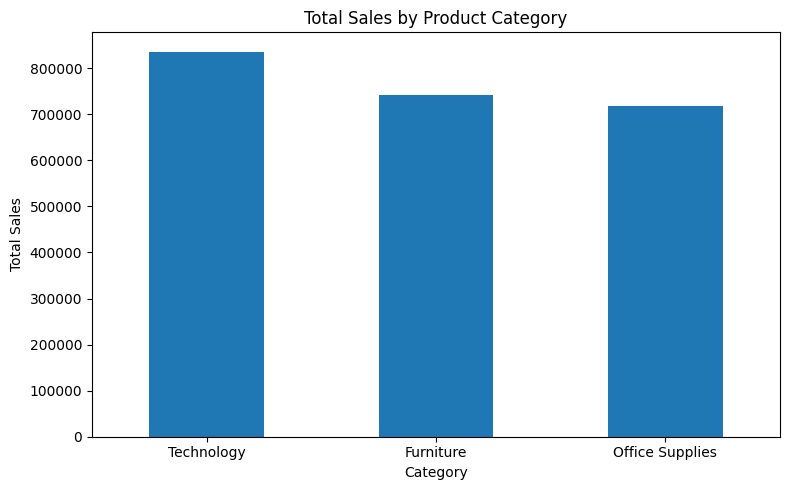

In [23]:
if {"Category", "Sales"}.issubset(df.columns):
    category_sales = df.groupby("Category")["Sales"].sum().sort_values(
        ascending=False
    )

    category_sales.plot(kind="bar", figsize=(8, 5))
    plt.title("Total Sales by Product Category")
    plt.xlabel("Category")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

Analyze sales and profit

1. Monthly sales analysis
Business question: Which month generates the highest sales?


In [28]:
print(df.columns.tolist())['S$0

['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount', 'Profit']


In [29]:
category_sales = df.groupby("Category")["Sales"].sum()

print(category_sales.sort_values(ascending=False))

Category
Technology         836154.0330
Furniture          741306.3133
Office Supplies    718735.2440
Name: Sales, dtype: float64


In [30]:
subcategory_sales = (
    df.groupby("Sub-Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(subcategory_sales)

Sub-Category
Phones         330007.0540
Chairs         327777.7610
Storage        223843.6080
Tables         206965.5320
Binders        203409.1690
Machines       189238.6310
Accessories    167380.3180
Copiers        149528.0300
Bookcases      114879.9963
Appliances     107532.1610
Furnishings     91683.0240
Paper           78224.1420
Supplies        46673.5380
Art             27107.0320
Envelopes       16476.4020
Labels          12444.9120
Fasteners        3024.2800
Name: Sales, dtype: float64


In [31]:
category_profit = (
    df.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print(category_profit)

Category
Technology         145454.9481
Office Supplies    122364.6608
Furniture           18421.8137
Name: Profit, dtype: float64


sales by region

In [32]:
region_sales = (
    df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(region_sales)

Region
West       725255.6365
East       678435.1960
Central    500782.8528
South      391721.9050
Name: Sales, dtype: float64


sales by visualization

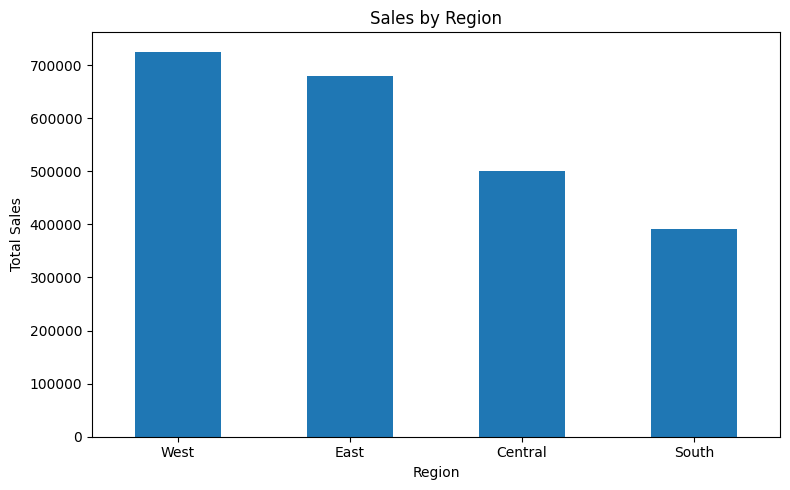

In [33]:
import matplotlib.pyplot as plt

region_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [34]:
print("Dataset shape:", df.shape)
print(df.head())
print(df.columns.tolist())

Dataset shape: (9977, 13)
        Ship Mode    Segment        Country             City       State  \
0    Second Class   Consumer  United States        Henderson    Kentucky   
1    Second Class   Consumer  United States        Henderson    Kentucky   
2    Second Class  Corporate  United States      Los Angeles  California   
3  Standard Class   Consumer  United States  Fort Lauderdale     Florida   
4  Standard Class   Consumer  United States  Fort Lauderdale     Florida   

   Postal Code Region         Category Sub-Category     Sales  Quantity  \
0        42420  South        Furniture    Bookcases  261.9600         2   
1        42420  South        Furniture       Chairs  731.9400         3   
2        90036   West  Office Supplies       Labels   14.6200         2   
3        33311  South        Furniture       Tables  957.5775         5   
4        33311  South  Office Supplies      Storage   22.3680         2   

   Discount    Profit  
0      0.00   41.9136  
1      0.00  219.5

# ##** Business Performance Analysis**

# Calculate important KPIs

In [43]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
total_records = len(df)
avg_discount = df["Discount"].mean()

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Quantity Sold:", total_quantity)
print("Total Records:", total_records)
print("Average Discount:", round(avg_discount * 100, 2), "%")

Total Sales: 2296195.59
Total Profit: 286241.42
Total Quantity Sold: 37820
Total Records: 9977
Average Discount: 15.63 %


# 2. Analyze category performance

In [44]:
category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Average_Discount=("Discount", "mean")
).round(2)

print(category_analysis.sort_values("Total_Sales", ascending=False))

                 Total_Sales  Total_Profit  Total_Quantity  Average_Discount
Category                                                                    
Technology         836154.03     145454.95            6939              0.13
Furniture          741306.31      18421.81            8020              0.17
Office Supplies    718735.24     122364.66           22861              0.16


In [45]:
top_subcategories = (
    df.groupby("Sub-Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_subcategories)

Sub-Category
Phones         330007.0540
Chairs         327777.7610
Storage        223843.6080
Tables         206965.5320
Binders        203409.1690
Machines       189238.6310
Accessories    167380.3180
Copiers        149528.0300
Bookcases      114879.9963
Appliances     107532.1610
Name: Sales, dtype: float64


# 4. Analyze regional performance

In [46]:
region_analysis = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).round(2)

print(region_analysis.sort_values("Total_Sales", ascending=False))

         Total_Sales  Total_Profit  Total_Quantity
Region                                            
West       725255.64     108329.81           12234
East       678435.20      91506.31           10609
Central    500782.85      39655.88            8768
South      391721.90      46749.43            6209


# Find loss-making sub-categories

In [48]:
subcategory_profit = (
     df.groupby("Sub-Category")["Profit"]
.sum()
.sort_values()
)
print("lowest-profit sub-categories:")
print(subcategory_profit.head(5))

lowest-profit sub-categories:
Sub-Category
Tables      -17725.4811
Bookcases    -3472.5560
Supplies     -1189.0995
Fasteners      949.5182
Machines      3384.7569
Name: Profit, dtype: float64


# Check data quality

In [49]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Missing values:
Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64

Duplicate rows: 0

Data types:
Ship Mode        object
Segment          object
Country          object
City             object
State            object
Postal Code       int64
Region           object
Category         object
Sub-Category     object
Sales           float64
Quantity          int64
Discount        float64
Profit          float64
dtype: object


## Category-wise Sales & Profit Analysis

In [9]:
import pandas as pd

df = pd.read_csv("SampleSuperstore.csv")

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(9994, 13)


## 1. Category analysis using Pandas

In [10]:

# Calculate category-wise business performance

category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Average_Discount=("Discount", "mean")
)

category_analysis = category_analysis.round(2)

print(category_analysis)


                 Total_Sales  Total_Profit  Total_Quantity  Average_Discount
Category                                                                    
Furniture          741999.80      18451.27            8028              0.17
Office Supplies    719047.03     122490.80           22906              0.16
Technology         836154.03     145454.95            6939              0.13


## 2. Visualize category-wise sales

In [ ]:

category_analysis["Total_Sales"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Total Sales by Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 3. Visualize category-wise profit

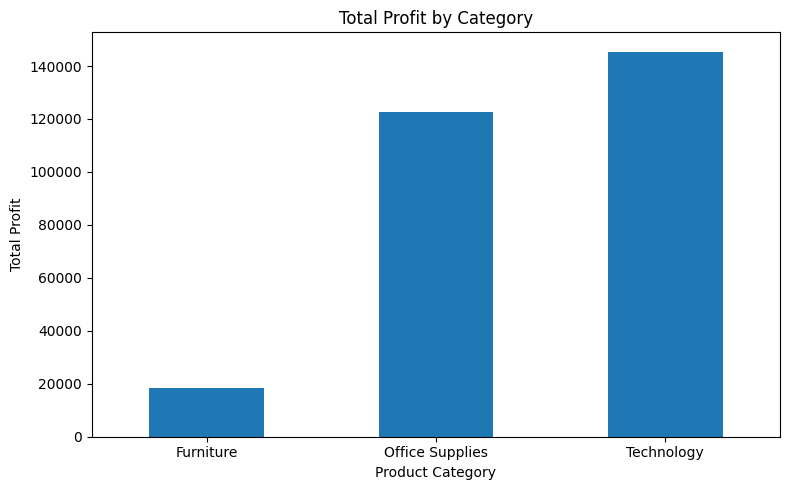

In [11]:

category_analysis["Total_Profit"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Total Profit by Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 4. Find the best-performing category

In [12]:

best_sales_category = category_analysis["Total_Sales"].idxmax()
best_profit_category = category_analysis["Total_Profit"].idxmax()

print("Highest Sales Category:", best_sales_category)
print("Highest Profit Category:", best_profit_category)


Highest Sales Category: Technology
Highest Profit Category: Technology


## Sub-category performance analysis

In [13]:

subcategory_analysis = df.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Average_Discount=("Discount", "mean")
)

subcategory_analysis = subcategory_analysis.round(2)

print(subcategory_analysis.sort_values(
    by="Total_Sales",
    ascending=False
))


              Total_Sales  Total_Profit  Total_Quantity  Average_Discount
Sub-Category                                                             
Phones          330007.05      44515.73            3289              0.15
Chairs          328449.10      26590.17            2356              0.17
Storage         223843.61      21278.83            3158              0.07
Tables          206965.53     -17725.48            1241              0.26
Binders         203412.73      30221.76            5974              0.37
Machines        189238.63       3384.76             440              0.31
Accessories     167380.32      41936.64            2976              0.08
Copiers         149528.03      55617.82             234              0.16
Bookcases       114880.00      -3472.56             868              0.21
Appliances      107532.16      18138.01            1729              0.17
Furnishings      91705.16      13059.14            3563              0.14
Paper            78479.21      34053.5

## Top 5 sub-categories by sales

In [14]:

top_5_sales = subcategory_analysis.nlargest(
    5, "Total_Sales"
)

print(top_5_sales[["Total_Sales", "Total_Profit"]])


              Total_Sales  Total_Profit
Sub-Category                           
Phones          330007.05      44515.73
Chairs          328449.10      26590.17
Storage         223843.61      21278.83
Tables          206965.53     -17725.48
Binders         203412.73      30221.76


## Identify loss-making sub-categories

In [15]:

loss_making = subcategory_analysis[
    subcategory_analysis["Total_Profit"] < 0
].sort_values("Total_Profit")

print(loss_making[["Total_Sales", "Total_Profit"]])


              Total_Sales  Total_Profit
Sub-Category                           
Tables          206965.53     -17725.48
Bookcases       114880.00      -3472.56
Supplies         46673.54      -1189.10


## 13.4 — Visualize top 10 sub-categories

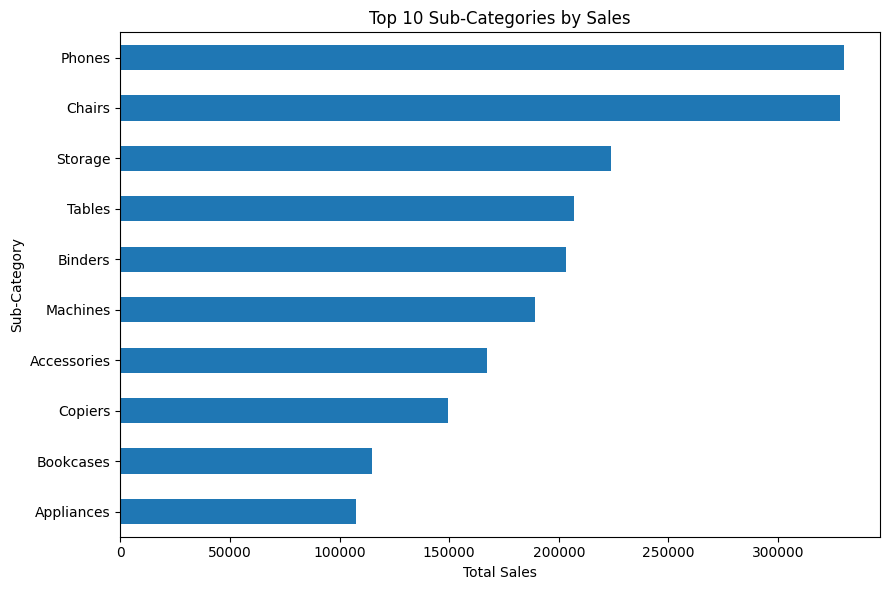

In [16]:

top_10 = subcategory_analysis.nlargest(10, "Total_Sales")

top_10["Total_Sales"].sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Top 10 Sub-Categories by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()


## Step 14.1 — Region-wise business performanceb

In [17]:

region_analysis = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Average_Discount=("Discount", "mean")
)

region_analysis = region_analysis.round(2)

print(region_analysis.sort_values(
    by="Total_Sales",
    ascending=False
))


         Total_Sales  Total_Profit  Total_Quantity  Average_Discount
Region                                                              
West       725457.82     108418.45           12266              0.11
East       678781.24      91522.78           10618              0.15
Central    501239.89      39706.36            8780              0.24
South      391721.90      46749.43            6209              0.15


## Step 14.2 — Compare regional sales

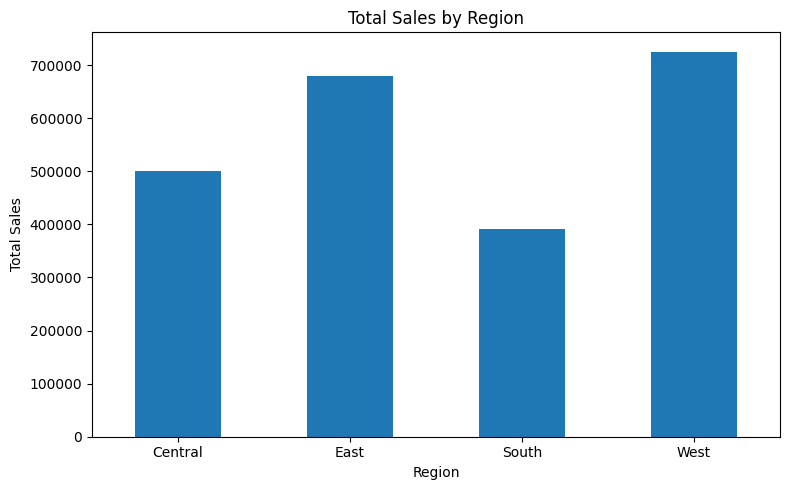

In [18]:

region_analysis["Total_Sales"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# Step 14.3 — Compare regional profit

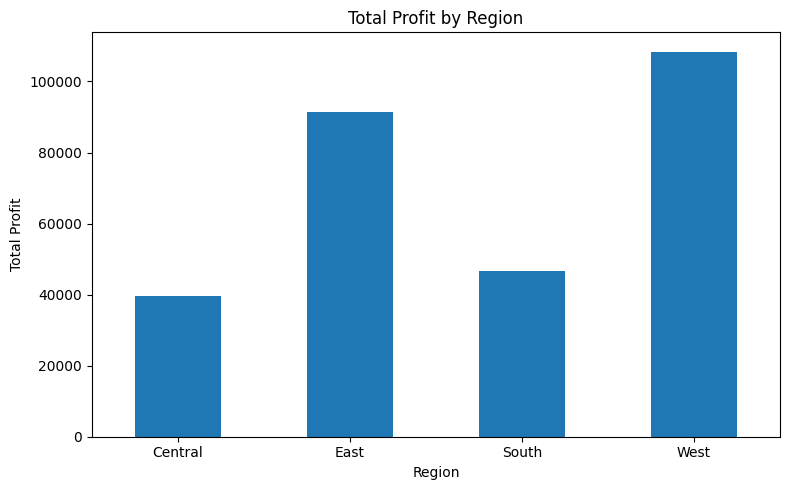

In [19]:

region_analysis["Total_Profit"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Step 14.4 — Automatically identify the best region

In [20]:

best_sales_region = region_analysis["Total_Sales"].idxmax()
best_profit_region = region_analysis["Total_Profit"].idxmax()

print("Highest Sales Region:", best_sales_region)
print("Highest Profit Region:", best_profit_region)


Highest Sales Region: West
Highest Profit Region: West


## Step 14.5 — State-wise sales analysis

In [21]:

state_sales = (
    df.groupby("State")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 States by Sales:")
print(state_sales.head(10))


Top 10 States by Sales:
State
California      457687.6315
New York        310876.2710
Texas           170188.0458
Washington      138641.2700
Pennsylvania    116511.9140
Florida          89473.7080
Illinois         80166.1010
Ohio             78258.1360
Michigan         76269.6140
Virginia         70636.7200
Name: Sales, dtype: float64


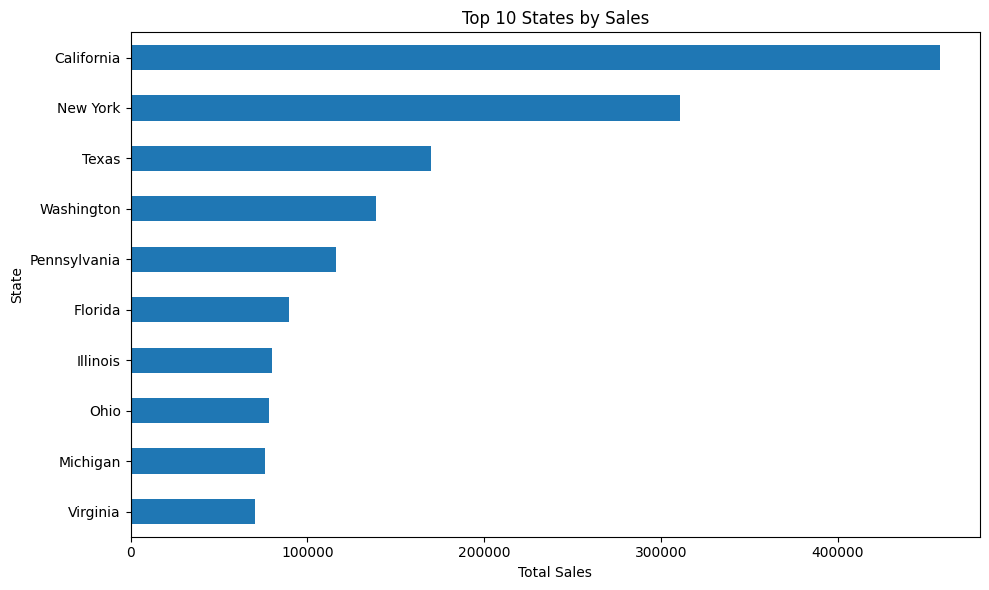

In [22]:

state_sales.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 States by Sales")
plt.xlabel("Total Sales")
plt.ylabel("State")
plt.tight_layout()
plt.show()


## Step 15.1 — Discount-wise sales and profit

In [23]:

discount_analysis = df.groupby("Discount").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Number_of_Records=("Sales", "count")
).round(2)

print(discount_analysis)


          Total_Sales  Total_Profit  Total_Quantity  Number_of_Records
Discount                                                              
0.00       1087908.47     320987.60           18267               4798
0.10         54369.35       9029.18             373                 94
0.15         27558.52       1418.99             198                 52
0.20        764594.37      90337.31           13660               3657
0.30        103226.66     -10369.28             849                227
0.32         14493.46      -2391.14             105                 27
0.40        116417.78     -23057.05             786                206
0.45          5484.97      -2493.11              45                 11
0.50         58918.54     -20506.43             241                 66
0.60          6644.70      -5944.66             501                138
0.70         40620.28     -40075.36            1660                418
0.80         16963.76     -30539.04            1188                300


## Step 15.2 — Visualize discount vs profit

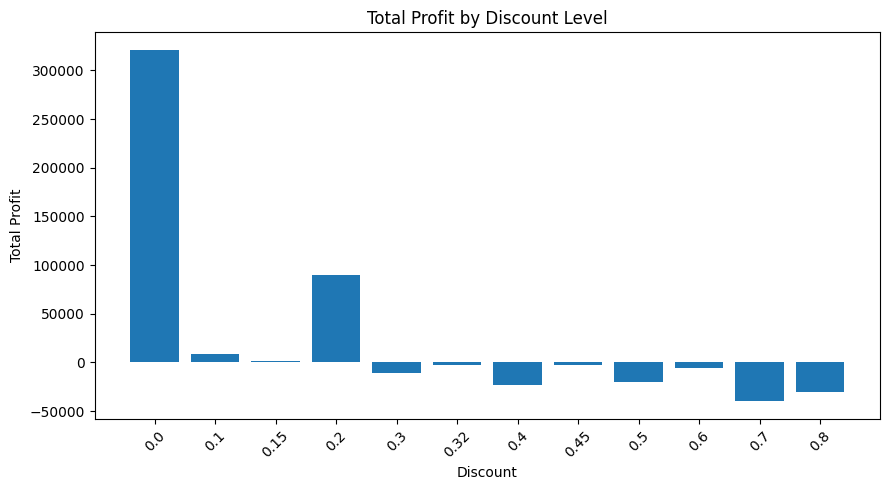

In [24]:

plt.figure(figsize=(9, 5))

plt.bar(
    discount_analysis.index.astype(str),
    discount_analysis["Total_Profit"]
)

plt.title("Total Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Step 15.3 — Calculate average profit at each discount

In [25]:

discount_avg_profit = df.groupby("Discount").agg(
    Average_Profit=("Profit", "mean"),
    Average_Sales=("Sales", "mean"),
    Records=("Profit", "count")
).round(2)

print(discount_avg_profit)


          Average_Profit  Average_Sales  Records
Discount                                        
0.00               66.90         226.74     4798
0.10               96.06         578.40       94
0.15               27.29         529.97       52
0.20               24.70         209.08     3657
0.30              -45.68         454.74      227
0.32              -88.56         536.79       27
0.40             -111.93         565.13      206
0.45             -226.65         498.63       11
0.50             -310.70         892.71       66
0.60              -43.08          48.15      138
0.70              -95.87          97.18      418
0.80             -101.80          56.55      300


## Step 15.4 — Analyze the relationship between discount and profit

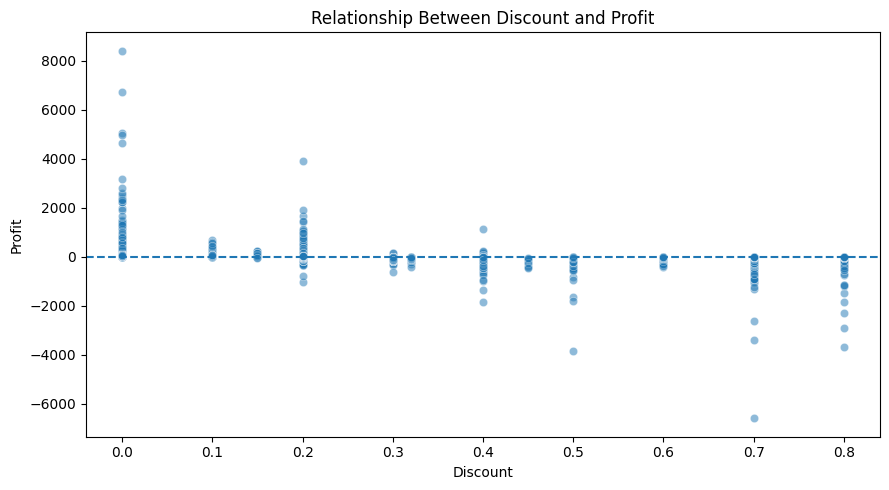

In [26]:

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    alpha=0.5
)

plt.title("Relationship Between Discount and Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.axhline(0, linestyle="--")
plt.tight_layout()
plt.show()


## Step 15.5 — Calculate correlation

In [27]:

correlation = df["Discount"].corr(df["Profit"])

print("Discount-Profit Correlation:", round(correlation, 3))


Discount-Profit Correlation: -0.219


## Step 16.1 — Segment-wise performance analysis

In [28]:

segment_analysis = df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Average_Discount=("Discount", "mean")
)

segment_analysis = segment_analysis.round(2)

print(segment_analysis.sort_values(
    by="Total_Sales",
    ascending=False
))


             Total_Sales  Total_Profit  Total_Quantity  Average_Discount
Segment                                                                 
Consumer      1161401.34     134119.21           19521              0.16
Corporate      706146.37      91979.13           11608              0.16
Home Office    429653.15      60298.68            6744              0.15


## Step 16.2 — Compare segment-wise sales

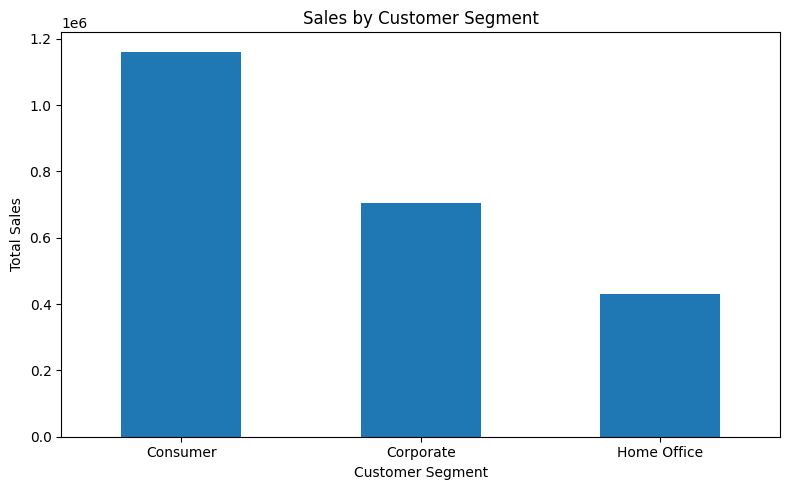

In [29]:

segment_analysis["Total_Sales"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Step 16.3 — Compare segment-wise profit

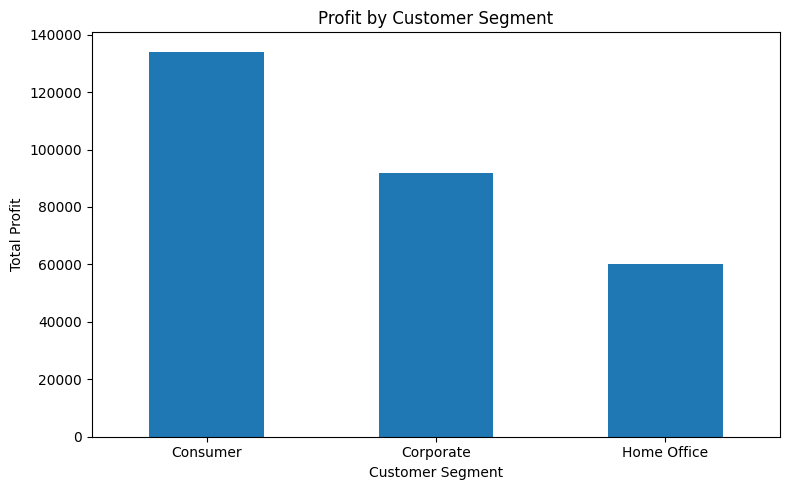

In [30]:

segment_analysis["Total_Profit"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Step 16.4 — Find the best-performing segment

In [31]:

best_sales_segment = segment_analysis["Total_Sales"].idxmax()
best_profit_segment = segment_analysis["Total_Profit"].idxmax()

print("Highest Sales Segment:", best_sales_segment)
print("Highest Profit Segment:", best_profit_segment)


Highest Sales Segment: Consumer
Highest Profit Segment: Consumer


## Step 16.5 — Segment-wise category analysis

In [35]:
segment_analysis = df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Average_Discount=("Discount", "mean")
).round(2)

print(segment_analysis.sort_values(by="Total_Sales", ascending=False))

             Total_Sales  Total_Profit  Total_Quantity  Average_Discount
Segment                                                                 
Consumer      1161401.34     134119.21           19521              0.16
Corporate      706146.37      91979.13           11608              0.16
Home Office    429653.15      60298.68            6744              0.15


Segment-wise Category Sales:
Category     Furniture  Office Supplies  Technology
Segment                                            
Consumer     391049.31        363952.14   406399.90
Corporate    229019.79        230676.46   246450.12
Home Office  121930.70        124418.43   183304.02


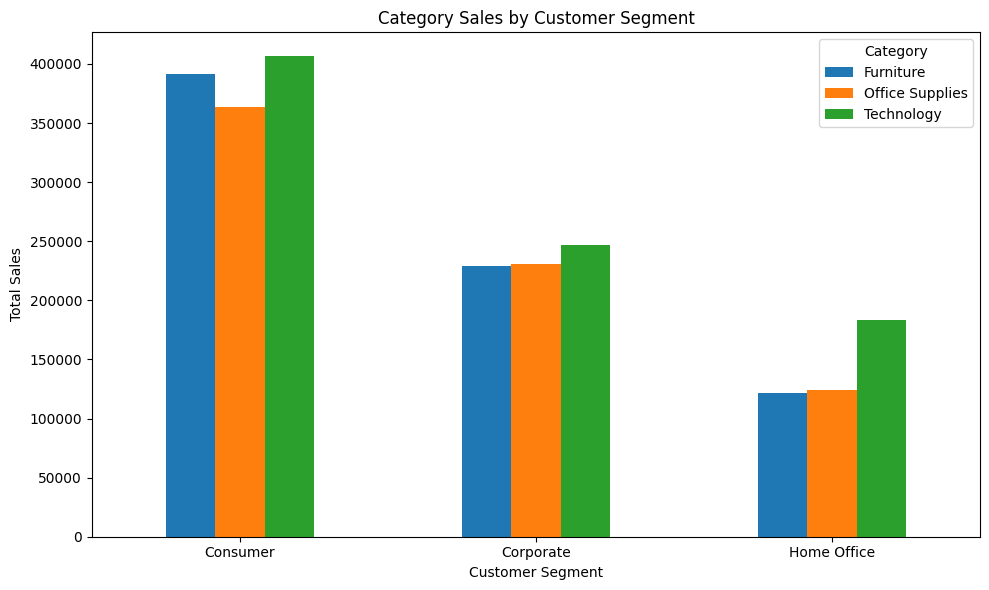

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

# Segment-wise category sales analysis
segment_category_sales = pd.pivot_table(
    df,
    index="Segment",
    columns="Category",
    values="Sales",
    aggfunc="sum",
    fill_value=0
)

print("Segment-wise Category Sales:")
print(segment_category_sales.round(2))

# Visualization
segment_category_sales.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Category Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.legend(title="Category")
plt.tight_layout()
plt.show()

## Generate Business Insights Report

In [38]:
# STEP 17: BUSINESS INSIGHTS REPORT

# 1. Best performing category
category_sales = df.groupby("Category")["Sales"].sum()
best_category = category_sales.idxmax()

# 2. Best performing sub-category
subcategory_sales = df.groupby("Sub-Category")["Sales"].sum()
best_subcategory = subcategory_sales.idxmax()

# 3. Best performing region
region_sales = df.groupby("Region")["Sales"].sum()
best_region = region_sales.idxmax()

# 4. Best customer segment by sales
segment_sales = df.groupby("Segment")["Sales"].sum()
best_segment = segment_sales.idxmax()

# 5. Most profitable category
category_profit = df.groupby("Category")["Profit"].sum()
most_profitable_category = category_profit.idxmax()

# 6. Loss-making sub-categories
subcategory_profit = df.groupby("Sub-Category")["Profit"].sum()
loss_subcategories = subcategory_profit[subcategory_profit < 0]

# Display report
print("=" * 45)
print("       BUSINESS INSIGHTS REPORT")
print("=" * 45)

print(f"Total Sales: {df['Sales'].sum():,.2f}")
print(f"Total Profit: {df['Profit'].sum():,.2f}")

print(f"\nBest Category by Sales: {best_category}")
print(f"Best Sub-Category by Sales: {best_subcategory}")
print(f"Best Region by Sales: {best_region}")
print(f"Best Customer Segment by Sales: {best_segment}")
print(f"Most Profitable Category: {most_profitable_category}")

print("\nLoss-Making Sub-Categories:")
if len(loss_subcategories) > 0:
    print(loss_subcategories.sort_values())
else:
    print("No loss-making sub-categories found.")

print("\n" + "=" * 45)

       BUSINESS INSIGHTS REPORT
Total Sales: 2,297,200.86
Total Profit: 286,397.02

Best Category by Sales: Technology
Best Sub-Category by Sales: Phones
Best Region by Sales: West
Best Customer Segment by Sales: Consumer
Most Profitable Category: Technology

Loss-Making Sub-Categories:
Sub-Category
Tables      -17725.4811
Bookcases    -3472.5560
Supplies     -1189.0995
Name: Profit, dtype: float64



## Step 18: Create and Download Report

In [39]:
# STEP 18: EXPORT BUSINESS REPORT

import pandas as pd
from google.colab import files

# Create business insights summary
report_data = {
    "Metric": [
        "Total Sales",
        "Total Profit",
        "Total Quantity Sold",
        "Average Discount (%)",
        "Best Category by Sales",
        "Best Sub-Category by Sales",
        "Best Region by Sales",
        "Best Customer Segment by Sales",
        "Most Profitable Category"
    ],
    "Value": [
        round(df["Sales"].sum(), 2),
        round(df["Profit"].sum(), 2),
        int(df["Quantity"].sum()),
        round(df["Discount"].mean() * 100, 2),
        df.groupby("Category")["Sales"].sum().idxmax(),
        df.groupby("Sub-Category")["Sales"].sum().idxmax(),
        df.groupby("Region")["Sales"].sum().idxmax(),
        df.groupby("Segment")["Sales"].sum().idxmax(),
        df.groupby("Category")["Profit"].sum().idxmax()
    ]
}

report_df = pd.DataFrame(report_data)

# Save report as CSV
report_df.to_csv("business_insights_report.csv", index=False)

print("Business Insights Report created successfully!")
print(report_df)

# Download report
files.download("business_insights_report.csv")

Business Insights Report created successfully!
                           Metric       Value
0                     Total Sales  2297200.86
1                    Total Profit   286397.02
2             Total Quantity Sold       37873
3            Average Discount (%)       15.62
4          Best Category by Sales  Technology
5      Best Sub-Category by Sales      Phones
6            Best Region by Sales        West
7  Best Customer Segment by Sales    Consumer
8        Most Profitable Category  Technology


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 19: Export the cleaned dataset

In [40]:
# Export cleaned dataset
df.to_csv("cleaned_sales_data.csv", index=False)

print("Cleaned dataset saved successfully!")

files.download("cleaned_sales_data.csv")

Cleaned dataset saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 20: Interactive Sales Dashboard using Plotly

In [2]:

# FIX: LOAD DATASET INTO df

import pandas as pd
from google.colab import files
import io

uploaded = files.upload()

# Read uploaded CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

# Check dataset
print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


Saving SampleSuperstore.csv to SampleSuperstore.csv
Dataset loaded successfully!
Shape: (9994, 13)
Columns: ['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount', 'Profit']


,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [3]:

# STEP 20: INTERACTIVE SALES DASHBOARD

import pandas as pd
import plotly.express as px
from IPython.display import display, HTML

# Check required columns
required_cols = [
    "Sales", "Profit", "Quantity",
    "Category", "Sub-Category", "Region", "Segment"
]

missing = [col for col in required_cols if col not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Prepare data
dashboard_df = df.copy()

dashboard_df["Sales"] = pd.to_numeric(
    dashboard_df["Sales"], errors="coerce"
)
dashboard_df["Profit"] = pd.to_numeric(
    dashboard_df["Profit"], errors="coerce"
)
dashboard_df["Quantity"] = pd.to_numeric(
    dashboard_df["Quantity"], errors="coerce"
)

dashboard_df = dashboard_df.dropna(
    subset=["Sales", "Profit", "Quantity"]
)

# KPI calculations
total_sales = dashboard_df["Sales"].sum()
total_profit = dashboard_df["Profit"].sum()
total_quantity = int(dashboard_df["Quantity"].sum())
avg_discount = (
    dashboard_df["Discount"].mean() * 100
    if "Discount" in dashboard_df.columns else 0
)

# Display KPI cards
display(HTML(f"""
<div style="display:flex;flex-wrap:wrap;gap:12px;">
  <div style="background:#e8f2ff;padding:18px;border-radius:10px;flex:1;min-width:150px;">
    <b>Total Sales</b><h2>{total_sales:,.2f}</h2>
  </div>
  <div style="background:#e8f8ed;padding:18px;border-radius:10px;flex:1;min-width:150px;">
    <b>Total Profit</b><h2>{total_profit:,.2f}</h2>
  </div>
  <div style="background:#fff3df;padding:18px;border-radius:10px;flex:1;min-width:150px;">
    <b>Total Quantity</b><h2>{total_quantity:,}</h2>
  </div>
  <div style="background:#f4eaff;padding:18px;border-radius:10px;flex:1;min-width:150px;">
    <b>Average Discount</b><h2>{avg_discount:.2f}%</h2>
  </div>
</div>
"""))

# 1. Category-wise Sales
category_sales = (
    dashboard_df.groupby("Category", as_index=False)["Sales"]
    .sum()
    .sort_values("Sales", ascending=False)
)

fig1 = px.bar(
    category_sales,
    x="Category",
    y="Sales",
    color="Category",
    title="Category-wise Sales",
    text_auto=".2s"
)
fig1.show()

# 2. Sub-category-wise Profit
subcategory_profit = (
    dashboard_df.groupby("Sub-Category", as_index=False)["Profit"]
    .sum()
    .sort_values("Profit", ascending=True)
)

fig2 = px.bar(
    subcategory_profit,
    x="Profit",
    y="Sub-Category",
    orientation="h",
    color="Profit",
    color_continuous_scale="RdYlGn",
    title="Sub-Category-wise Profit and Loss"
)
fig2.show()

# 3. Segment-wise Sales
segment_sales = (
    dashboard_df.groupby("Segment", as_index=False)["Sales"]
    .sum()
)

fig3 = px.pie(
    segment_sales,
    names="Segment",
    values="Sales",
    hole=0.4,
    title="Segment-wise Sales Distribution"
)
fig3.show()

# 4. Region-wise Performance
region_performance = (
    dashboard_df.groupby("Region", as_index=False)
    [["Sales", "Profit"]].sum()
)

fig4 = px.bar(
    region_performance,
    x="Region",
    y=["Sales", "Profit"],
    barmode="group",
    title="Region-wise Sales vs Profit"
)
fig4.show()

# 5. Monthly Sales Trend (if Order Date exists)
date_col = next(
    (col for col in ["Order Date", "Order_Date", "Date"]
     if col in dashboard_df.columns),
    None
)

if date_col:
    dashboard_df[date_col] = pd.to_datetime(
        dashboard_df[date_col], errors="coerce"
    )

    monthly_data = dashboard_df.dropna(
        subset=[date_col]
    ).copy()

    monthly_data["Month"] = (
        monthly_data[date_col].dt.to_period("M").astype(str)
    )

    monthly_sales = (
        monthly_data.groupby("Month", as_index=False)["Sales"]
        .sum()
        .sort_values("Month")
    )

    fig5 = px.line(
        monthly_sales,
        x="Month",
        y="Sales",
        markers=True,
        title="Monthly Sales Trend"
    )
    fig5.show()
else:
    print("Monthly trend skipped: Order Date column not found.")

print("Interactive Sales Dashboard generated successfully!")


Monthly trend skipped: Order Date column not found.
Interactive Sales Dashboard generated successfully!


## Step 21: Export Business Insights to CSV

In [4]:

# STEP 21: EXPORT BUSINESS INSIGHTS

import pandas as pd
from google.colab import files

# 1. Category-wise performance
category_report = (
    df.groupby("Category", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)

category_report.to_csv("category_performance.csv", index=False)

# 2. Sub-category profit and loss
subcategory_report = (
    df.groupby("Sub-Category", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
)

subcategory_report["Status"] = subcategory_report[
    "Total_Profit"
].apply(lambda x: "Profitable" if x > 0 else
        ("Break-even" if x == 0 else "Loss"))

subcategory_report = subcategory_report.sort_values(
    "Total_Profit"
)

subcategory_report.to_csv(
    "subcategory_profit_loss.csv", index=False
)

# 3. Region-wise performance
region_report = (
    df.groupby("Region", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)

region_report.to_csv("region_performance.csv", index=False)

# Display reports
print("CATEGORY PERFORMANCE")
display(category_report)

print("SUB-CATEGORY PROFIT AND LOSS")
display(subcategory_report)

print("REGION PERFORMANCE")
display(region_report)

print("All three reports created successfully!")

# Download reports one by one
files.download("category_performance.csv")


CATEGORY PERFORMANCE


,Category,Total_Sales,Total_Profit,Total_Quantity
2,Technology,836154.0330,145454.9481,6939
0,Furniture,741999.7953,18451.2728,8028
1,Office Supplies,719047.0320,122490.8008,22906


SUB-CATEGORY PROFIT AND LOSS


,Sub-Category,Total_Sales,Total_Profit,Status
16,Tables,206965.5320,-17725.4811,Loss
4,Bookcases,114879.9963,-3472.5560,Loss
15,Supplies,46673.5380,-1189.0995,Loss
8,Fasteners,3024.2800,949.5182,Profitable
11,Machines,189238.6310,3384.7569,Profitable
10,Labels,12486.3120,5546.2540,Profitable
2,Art,27118.7920,6527.7870,Profitable
7,Envelopes,16476.4020,6964.1767,Profitable
9,Furnishings,91705.1640,13059.1436,Profitable
1,Appliances,107532.1610,18138.0054,Profitable


REGION PERFORMANCE


,Region,Total_Sales,Total_Profit
3,West,725457.8245,108418.4489
1,East,678781.2400,91522.7800
0,Central,501239.8908,39706.3625
2,South,391721.9050,46749.4303


All three reports created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:

files.download("subcategory_profit_loss.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:

files.download("region_performance.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 22: Automated Business Recommendations

In [7]:

# STEP 22: FINAL BUSINESS RECOMMENDATIONS

import pandas as pd
from google.colab import files

# Category-wise analysis
category_report = (
    df.groupby("Category", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
)

# Sub-category-wise analysis
subcategory_report = (
    df.groupby("Sub-Category", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
)

# Region-wise analysis
region_report = (
    df.groupby("Region", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
)

# Find best performers
best_category = category_report.loc[
    category_report["Total_Sales"].idxmax()
]

best_profit_category = category_report.loc[
    category_report["Total_Profit"].idxmax()
]

best_region = region_report.loc[
    region_report["Total_Profit"].idxmax()
]

# Identify loss-making sub-categories
loss_making = subcategory_report[
    subcategory_report["Total_Profit"] < 0
].sort_values("Total_Profit")

# Generate recommendations
recommendations = [
    {
        "Area": "Sales Leader",
        "Finding": str(best_category["Category"]),
        "Recommendation":
            "Study this category's successful products and "
            "maintain inventory according to demand."
    },
    {
        "Area": "Profit Leader",
        "Finding": str(best_profit_category["Category"]),
        "Recommendation":
            "Analyze the products and pricing strategies "
            "contributing to this category's profit."
    },
    {
        "Area": "Best Region by Profit",
        "Finding": str(best_region["Region"]),
        "Recommendation":
            "Study this region's performance and identify "
            "practices that may work in other regions."
    }
]

for _, row in loss_making.iterrows():
    recommendations.append({
        "Area": "Loss-making Sub-Category",
        "Finding": row["Sub-Category"],
        "Recommendation":
            "Review discounts, costs, pricing and product "
            "returns before deciding corrective actions."
    })

recommendation_df = pd.DataFrame(recommendations)

# Display results
print("TOP CATEGORY BY SALES:", best_category["Category"])
print("MOST PROFITABLE CATEGORY:", best_profit_category["Category"])
print("TOP REGION BY PROFIT:", best_region["Region"])

print("\nLOSS-MAKING SUB-CATEGORIES:")
if loss_making.empty:
    print("No loss-making sub-categories found.")
else:
    display(loss_making)

print("\nBUSINESS RECOMMENDATIONS:")
display(recommendation_df)

# Export recommendations
recommendation_df.to_csv(
    "business_recommendations.csv", index=False
)

files.download("business_recommendations.csv")

print("Business recommendations report exported successfully!")


TOP CATEGORY BY SALES: Technology
MOST PROFITABLE CATEGORY: Technology
TOP REGION BY PROFIT: West

LOSS-MAKING SUB-CATEGORIES:


,Sub-Category,Total_Sales,Total_Profit
16,Tables,206965.5320,-17725.4811
4,Bookcases,114879.9963,-3472.5560
15,Supplies,46673.5380,-1189.0995



BUSINESS RECOMMENDATIONS:


,Area,Finding,Recommendation
0,Sales Leader,Technology,Study this category's successful products and ...
1,Profit Leader,Technology,Analyze the products and pricing strategies co...
2,Best Region by Profit,West,Study this region's performance and identify p...
3,Loss-making Sub-Category,Tables,"Review discounts, costs, pricing and product r..."
4,Loss-making Sub-Category,Bookcases,"Review discounts, costs, pricing and product r..."
5,Loss-making Sub-Category,Supplies,"Review discounts, costs, pricing and product r..."


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Business recommendations report exported successfully!


## Step 24: Generate Project README

In [8]:

# STEP 24: CREATE PROJECT README

from google.colab import files

readme_content = """
# Sales Data Analysis and Business Insights

## Project Overview
This project analyzes sales data to identify business trends,
profitability, category performance, and regional performance.

## Objectives
- Analyze total sales and total profit.
- Identify top-performing product categories.
- Compare customer segment performance.
- Analyze regional sales and profitability.
- Identify loss-making sub-categories.
- Generate actionable business recommendations.

## Tools and Technologies
- Python
- Pandas
- Plotly
- Google Colab
- Jupyter Notebook

## Key Performance Indicators
- Total Sales
- Total Profit
- Total Quantity Sold
- Average Discount

## Analysis Performed
1. Data cleaning and preparation
2. Category-wise sales analysis
3. Sub-category profit and loss analysis
4. Segment-wise sales analysis
5. Region-wise performance analysis
6. Monthly sales trend (when date data is available)
7. Business recommendations

## Project Output Files
- business_insights_report.csv
- cleaned_sales_data.csv
- category_performance.csv
- subcategory_profit_loss.csv
- region_performance.csv
- business_recommendations.csv

## How to Run
1. Open the notebook in Google Colab.
2. Upload the sales dataset CSV.
3. Run the notebook cells in order.
4. Review the charts and generated CSV reports.

## Business Value
The analysis helps identify sales opportunities,
understand profitability, and highlight areas
that may require pricing or discount improvements.

## Author
Your Name

## Note
Actual findings and recommendations depend on the
dataset used for analysis.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme_content.strip() + "\n")

print("README.md created successfully!")

files.download("README.md")


README.md created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>